# Prédiction de maladie cardiaque : enrichissement par l'ontologie HPO

**Question de recherche** : enrichir le dataset *Heart Disease* (UCI / Kaggle) avec des connaissances de la *Human Phenotype Ontology* (`hp.owl`) améliore-t-il les performances de modèles de ML classiques ?

**Démarche (étape par étape)**
1. Préparer les données et **décoder correctement** les variables
2. Établir une **baseline** de ML classique *sans ontologie*, avec un protocole d'évaluation fixe
3. **Lier** le dataset à l'ontologie (mapping colonnes / valeurs → termes HPO)
4. **Enrichir** le dataset à partir de ce lien (plusieurs stratégies)
5. **Comparer** chaque variante enrichie à la baseline avec le même protocole et des tests statistiques

## 1. Données

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

SEED = 42
raw = pd.read_csv('heart.csv', encoding='utf-8-sig')
print(raw.shape)
raw.head()

(303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


### 1.1 Vérification de l'encodage

La version Kaggle de ce dataset **n'utilise pas les mêmes codes** que l'UCI original (Cleveland). Ça compte beaucoup ici : relier `cp = 0` au terme HPO *Angina pectoris* alors qu'il code en fait *asymptomatique* fausserait tout l'enrichissement.

On déduit l'encodage réel en croisant les effectifs avec ceux publiés par l'UCI (303 patients) et avec la direction de l'association à la cible :

| Variable | Code Kaggle → signification | Indice |
|---|---|---|
| `target` | **conservé tel quel (convention Kaggle)**. Remarque : d'après les données, `target=0` regroupe les profils les plus pathologiques | 138 « 0 » contre 139 malades UCI ; `target=0` a plus d'`oldpeak` et d'`exang` et moins de `thalach` |
| `cp` | 0 = asymptomatique, 1 = angor atypique, 2 = douleur non angineuse, 3 = angor typique | `cp=0` (143) ≈ asymptomatique UCI (144), et c'est la catégorie la plus « malade » |
| `restecg` | 0 = hypertrophie VG, 1 = normal, 2 = anomalie ST-T | effectifs UCI : normal 151, HVG 148, ST-T 4 |
| `slope` | 0 = descendante, 1 = plate, 2 = ascendante | `slope=2` (142) ≈ ascendante UCI (142), associée aux patients sains |
| `thal` | 1 = défaut fixe, 2 = normal, 3 = défaut réversible (0 = manquant) | effectifs UCI : normal 166, fixe 18, réversible 117 |
| `ca` | 0–3 vaisseaux (4 = manquant) | |

La cellule suivante vérifie ces déductions.

In [2]:
for col in ['cp', 'restecg', 'slope', 'thal']:
    display(pd.crosstab(raw[col], raw['target'], normalize='index').round(2).rename(columns={0: 'target=0', 1: 'target=1'}))

target,target=0,target=1
cp,,
0,0.73,0.27
1,0.18,0.82
2,0.21,0.79
3,0.30,0.70


target,target=0,target=1
restecg,,
0,0.54,0.46
1,0.37,0.63
2,0.75,0.25


target,target=0,target=1
slope,,
0,0.57,0.43
1,0.65,0.35
2,0.25,0.75


target,target=0,target=1
thal,,
0,0.50,0.50
1,0.67,0.33
2,0.22,0.78
3,0.76,0.24


### 1.2 Nettoyage et décodage

In [3]:
df = raw[(raw['ca'] < 4) & (raw['thal'] > 0)].copy()   # valeurs manquantes codées 4 / 0

df = df.rename(columns={
    'cp': 'chest_pain_type', 'trestbps': 'resting_blood_pressure', 'chol': 'cholesterol',
    'fbs': 'fasting_blood_sugar', 'restecg': 'resting_ecg', 'thalach': 'max_heart_rate',
    'exang': 'exercise_induced_angina', 'oldpeak': 'st_depression', 'slope': 'st_slope',
    'ca': 'num_major_vessels', 'thal': 'thalassemia'})

decode = {
    'sex': {0: 'female', 1: 'male'},
    'chest_pain_type': {0: 'asymptomatic', 1: 'atypical angina', 2: 'non-anginal pain', 3: 'typical angina'},
    'fasting_blood_sugar': {0: '<=120 mg/dl', 1: '>120 mg/dl'},
    'resting_ecg': {0: 'left ventricular hypertrophy', 1: 'normal', 2: 'ST-T abnormality'},
    'exercise_induced_angina': {0: 'no', 1: 'yes'},
    'st_slope': {0: 'downsloping', 1: 'flat', 2: 'upsloping'},
    'thalassemia': {1: 'fixed defect', 2: 'normal', 3: 'reversible defect'},
}
for col, m in decode.items():
    df[col] = df[col].map(m)

# cible : colonne 'target' conservée telle quelle (convention Kaggle)

NUM_FEATS = ['age', 'resting_blood_pressure', 'cholesterol', 'max_heart_rate', 'st_depression', 'num_major_vessels']
CAT_FEATS = list(decode)
TARGET = 'target'

print(df.shape, '| proportion target=1 :', round(df[TARGET].mean(), 3))
df.head()

(296, 14) | proportion target=1 : 0.541


,age,sex,chest_pain_type,resting_blood_pressure,cholesterol,fasting_blood_sugar,resting_ecg,max_heart_rate,exercise_induced_angina,st_depression,st_slope,num_major_vessels,thalassemia,target
0,63,male,typical angina,145,233,>120 mg/dl,left ventricular hypertrophy,150,no,2.3,downsloping,0,fixed defect,1
1,37,male,non-anginal pain,130,250,<=120 mg/dl,normal,187,no,3.5,downsloping,0,normal,1
2,41,female,atypical angina,130,204,<=120 mg/dl,left ventricular hypertrophy,172,no,1.4,upsloping,0,normal,1
3,56,male,atypical angina,120,236,<=120 mg/dl,normal,178,no,0.8,upsloping,0,normal,1
4,57,female,asymptomatic,120,354,<=120 mg/dl,normal,163,yes,0.6,upsloping,0,normal,1


## 2. Baseline : ML classique sans ontologie

**Protocole fixe** (réutilisé pour toutes les variantes enrichies) :
- Avec seulement 296 patients, un seul découpage train/test est trop bruité. On utilise donc une **validation croisée stratifiée 5 folds répétée 10 fois** (50 évaluations par modèle), avec les mêmes folds pour toutes les variantes.
- Le prétraitement est fait *dans* le pipeline (pas de fuite) : one-hot pour les catégorielles, standardisation pour les numériques.
- Métriques : ROC AUC (principale), accuracy, F1, rappel.

In [4]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.naive_bayes import GaussianNB

CV = RepeatedStratifiedKFold(n_splits=5, n_repeats=10, random_state=SEED)
SCORING = {'roc_auc': 'roc_auc', 'accuracy': 'accuracy', 'f1': 'f1', 'recall': 'recall'}

MODELS = {
    'LogReg':        LogisticRegression(max_iter=2000),
    'KNN':           KNeighborsClassifier(n_neighbors=7),
    'SVC (RBF)':     SVC(),
    'DecisionTree':  DecisionTreeClassifier(max_depth=4, random_state=SEED),
    'RandomForest':  RandomForestClassifier(n_estimators=300, random_state=SEED),
    'GradBoosting':  GradientBoostingClassifier(random_state=SEED),
    'NaiveBayes':    GaussianNB(),
}

def make_preprocessor(num_feats, cat_feats, passthrough=()):
    return ColumnTransformer([
        ('num', StandardScaler(), list(num_feats)),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), list(cat_feats)),
        ('bin', 'passthrough', list(passthrough)),   # futures features ontologiques (0/1)
    ])

def evaluate(X, y, num_feats, cat_feats, passthrough=(), models=MODELS):
    '''Évalue chaque modèle avec le protocole fixe. Retourne (résumé, scores bruts par fold).'''
    summary, raw_scores = [], {}
    for name, model in models.items():
        pipe = make_pipeline(make_preprocessor(num_feats, cat_feats, passthrough), model)
        s = cross_validate(pipe, X, y, cv=CV, scoring=SCORING, n_jobs=-1)
        raw_scores[name] = s['test_roc_auc']
        summary.append({'model': name, **{f'{m}_mean': s[f'test_{m}'].mean() for m in SCORING},
                        'roc_auc_std': s['test_roc_auc'].std()})
    return pd.DataFrame(summary).set_index('model').sort_values('roc_auc_mean', ascending=False), raw_scores

In [5]:
X_base, y = df[NUM_FEATS + CAT_FEATS], df[TARGET]
baseline, baseline_scores = evaluate(X_base, y, NUM_FEATS, CAT_FEATS)
baseline.round(3)

,roc_auc_mean,accuracy_mean,f1_mean,recall_mean,roc_auc_std
model,,,,,
LogReg,0.911,0.846,0.862,0.888,0.033
RandomForest,0.902,0.822,0.838,0.852,0.036
SVC (RBF),0.902,0.832,0.851,0.883,0.035
KNN,0.891,0.828,0.846,0.871,0.038
NaiveBayes,0.880,0.800,0.820,0.843,0.041
GradBoosting,0.878,0.798,0.814,0.825,0.039
DecisionTree,0.800,0.760,0.785,0.813,0.055


## 3. Chargement de l'ontologie HPO

`owlready2` charge `hp.owl` (version 2026-09-01). On ajoute quelques fonctions utilitaires pour explorer les termes, et c'est cette base qui servira au mapping (étape suivante).

In [6]:
import os
from owlready2 import get_ontology, ThingClass

hpo = get_ontology('file://' + os.path.abspath('hp.owl')).load()
HP = lambda hp_id: hpo.search_one(iri=f'*{hp_id.replace(":", "_")}')

def parents(term):
    return [p for p in term.is_a if isinstance(p, ThingClass)]

def ancestors(term):
    '''Ancêtres is_a (sans le terme lui-même ni owl:Thing).'''
    return {a for a in term.ancestors() if a is not term and a.name.startswith('HP_')}

def show(hp_id):
    t = HP(hp_id)
    print(f'{t.name}  {t.label.first()}')
    print('   synonymes :', list(t.hasExactSynonym)[:4])
    print('   parents   :', [p.label.first() for p in parents(t)])
    print('   nb ancêtres :', len(ancestors(t)))

n_terms = sum(1 for c in hpo.classes() if c.name.startswith('HP_') and not c.deprecated)
print(f'{n_terms} termes HPO actifs')
show('HP:0001681')   # Angina pectoris

19894 termes HPO actifs
HP_0001681  Angina pectoris
   synonymes : []
   parents   : ['Abnormal cardiovascular system physiology']
   nb ancêtres : 4


## 4. Étape 1 : règles et seuils cliniques proposés par le LLM

**Méthode** : on enrichit le dataset avec des colonnes binaires issues de HPO. Les seuils **partent de la clinique** et sont **ajustés sur les données d'entraînement** par un LLM.

1. **Une seule fois, sans données** : `gemma4:12b` reçoit la description des colonnes et des candidats HPO réels tirés de `hp.owl` (condition *grounded*). Il propose :
   - pour chaque variable numérique, une règle `variable opérateur seuil` avec le **seuil clinique standard** et sa classe HPO ;
   - pour chaque variable catégorielle, les modalités anormales et leur classe HPO.
2. **Dans chaque fold** (section 5), le LLM ajuste les seuils numériques en ne voyant que des statistiques sur les patients d'entraînement.

Le code est dans [`threshold_llm.py`](threshold_llm.py) (il réutilise [`llm_mapping.py`](llm_mapping.py)). Les réponses sont en cache dans `llm_thresholds/`. **Prérequis** : le serveur Ollama doit tourner (`~/.local/ollama/bin/ollama serve`).

In [7]:
import importlib, llm_mapping as llm, threshold_llm as tl
importlib.reload(llm); importlib.reload(tl)

hpo_index = llm.HPOIndex(hpo)
rules_record = tl.get_rules(df, NUM_FEATS, CAT_FEATS, hpo_index)
num_rules_all, cat_rules_all = tl.validate(rules_record, df, hpo_index, NUM_FEATS, CAT_FEATS)
num_rules = num_rules_all[num_rules_all.usable].reset_index(drop=True)
cat_rules = cat_rules_all[cat_rules_all.usable].reset_index(drop=True)

print(f"{len(num_rules)}/{len(num_rules_all)} règles numériques et {len(cat_rules)}/{len(cat_rules_all)} règles catégorielles valides")
display(num_rules[['rule_id', 'group', 'variable', 'operator', 'clinical_threshold', 'hp_id', 'hp_label_hpo', 'match_type', 'status']])
display(cat_rules[['rule_id', 'variable', 'values', 'hp_id', 'hp_label_hpo', 'match_type', 'status']])

7/7 règles numériques et 11/11 règles catégorielles valides


,rule_id,group,variable,operator,clinical_threshold,hp_id,hp_label_hpo,match_type,status
0,N0,G0,resting_blood_pressure,>=,140,HP:0000822,Hypertension,approximate,ok
1,N1,G0,resting_blood_pressure,>=,140,HP:0004421,Elevated systolic blood pressure,exact,ok
2,N2,G1,cholesterol,>=,240,HP:0003124,Hypercholesterolemia,exact,ok
3,N3,G2,st_depression,>,1,HP:0012250,ST segment depression,approximate,ok
4,N4,G3,num_major_vessels,>,0,HP:0005181,Premature coronary artery atherosclerosis,broader,ok
5,N5,G3,num_major_vessels,>,0,HP:0012436,Nonocclusive coronary artery atherosclerosis,broader,ok
6,N6,G3,num_major_vessels,>,0,HP:0005145,Coronary artery stenosis,approximate,ok


,rule_id,variable,values,hp_id,hp_label_hpo,match_type,status
0,C0,chest_pain_type,"[atypical angina, typical angina]",HP:0001681,Angina pectoris,approximate,ok
1,C1,chest_pain_type,"[atypical angina, non-anginal pain, typical an...",HP:0100749,Chest pain,approximate,ok
2,C2,fasting_blood_sugar,[>120 mg/dl],HP:0003074,Hyperglycemia,exact,ok
3,C3,fasting_blood_sugar,[>120 mg/dl],HP:0000819,Diabetes mellitus,broader,ok
4,C4,fasting_blood_sugar,[>120 mg/dl],HP:0005978,Type II diabetes mellitus,broader,ok
5,C5,fasting_blood_sugar,[>120 mg/dl],HP:0000831,Insulin-resistant diabetes mellitus,broader,ok
6,C6,resting_ecg,[left ventricular hypertrophy],HP:0001712,Left ventricular hypertrophy,exact,ok
7,C7,resting_ecg,"[ST-T abnormality, left ventricular hypertrophy]",HP:0003115,Abnormal EKG,broader,ok
8,C8,exercise_induced_angina,[yes],HP:0001681,Angina pectoris,exact,ok
9,C9,st_slope,"[downsloping, flat]",HP:0012249,Abnormal ST segment,approximate,ok


### 4.1 Contrôle de la mémoire du LLM

Le dataset de Cleveland est très connu : le LLM pourrait proposer des seuils « optimaux » appris sur ce dataset plutôt que des seuils cliniques. On compare donc ses seuils de départ aux **valeurs des recommandations cliniques**.

In [8]:
GUIDELINES = {   # seuils de référence (cf. mapping manuel de heart_ontology.ipynb)
    'resting_blood_pressure': (140, 'ESC/ESH : HTA de grade 1'),
    'cholesterol': (240, 'NCEP ATP III : cholestérol total élevé'),
    'st_depression': (1, "AHA : critère d'un test d'effort positif (≥ 1 mm)"),
    'num_major_vessels': (1, '≥ 1 vaisseau atteint'),
}
groups = num_rules.drop_duplicates('group')
pd.DataFrame([{'groupe': g.group, 'variable': g.variable, 'règle LLM': f'{g.operator} {g.clinical_threshold:g}',
               'recommandation': f"≥ {GUIDELINES[g.variable][0]}" if g.variable in GUIDELINES else '—',
               'source': GUIDELINES.get(g.variable, (None, '—'))[1]} for g in groups.itertuples()])

,groupe,variable,règle LLM,recommandation,source
0,G0,resting_blood_pressure,>= 140,≥ 140,ESC/ESH : HTA de grade 1
1,G1,cholesterol,>= 240,≥ 240,NCEP ATP III : cholestérol total élevé
2,G2,st_depression,> 1,≥ 1,AHA : critère d'un test d'effort positif (≥ 1 mm)
3,G3,num_major_vessels,> 0,≥ 1,≥ 1 vaisseau atteint


## 5. Étape 2 : ajustement des seuils dans chaque fold, par le LLM

Pour chacun des 50 folds (les **mêmes** que la baseline) et chaque critère :
1. sur les **patients d'entraînement uniquement**, le code calcule une table de seuils candidats autour du seuil clinique (± 1 écart-type), avec pour chacun la part de patients annotés et le score du critère ;
2. `gemma4:12b` choisit le seuil, en privilégiant le critère sans s'éloigner de la plausibilité clinique.

**Deux critères comparés** :
- **AUC** de la colonne binaire (plus haut = mieux). Le coefficient de Gini, égal à 2 × AUC − 1, donnerait exactement les mêmes choix ;
- **impureté de Gini** pondérée après découpage, le critère des arbres de décision (plus bas = mieux).

Le LLM ne voit **jamais les patients de test**, ni aucun patient individuellement : il n'y a pas de fuite. La méthode (fenêtre, nombre de candidats, critères) a été **fixée avant de regarder les résultats**.

100 appels au LLM au premier lancement (environ 45 s chacun), puis lecture du cache.

In [9]:
FOLDS = list(CV.split(df, y))   # mêmes folds que la baseline (même ordre)

fold_thresholds = {}            # {critère: [ {groupe: seuil} pour chaque fold ]}
for crit in tl.CRITERIA:
    fold_thresholds[crit] = []
    for k, (tr, te) in enumerate(FOLDS):
        rec = tl.adjust_fold(num_rules, df.iloc[tr], y.iloc[tr], crit, k)
        fold_thresholds[crit].append({g: v['threshold'] for g, v in rec['thresholds'].items()})
    print(f'✔ {crit} : {len(fold_thresholds[crit])} folds')

✔ auc : 50 folds
✔ gini : 50 folds


### 5.1 Stabilité des seuils ajustés

Un seuil qui change beaucoup d'un fold à l'autre est peu fiable. On regarde aussi à quelle fréquence le LLM **garde le seuil clinique**.

,critère,groupe,règle,clinique,moyenne,écart-type,min,max,% folds = clinique
0,auc,G0,resting_blood_pressure >=,140,138.64,6.28,122.50,145.50,36.00
1,auc,G1,cholesterol >=,240,251.35,9.94,227.50,273.50,0.00
2,auc,G2,st_depression >,1,0.89,0.28,0.65,1.70,0.00
3,auc,G3,num_major_vessels >,0,0.00,0.00,0.00,0.00,100.00
4,gini,G0,resting_blood_pressure >=,140,141.69,3.76,122.50,153.00,20.00
5,gini,G1,cholesterol >=,240,252.36,10.41,223.50,277.50,0.00
6,gini,G2,st_depression >,1,1.32,0.45,0.75,2.05,0.00
7,gini,G3,num_major_vessels >,0,0.00,0.00,0.00,0.00,100.00


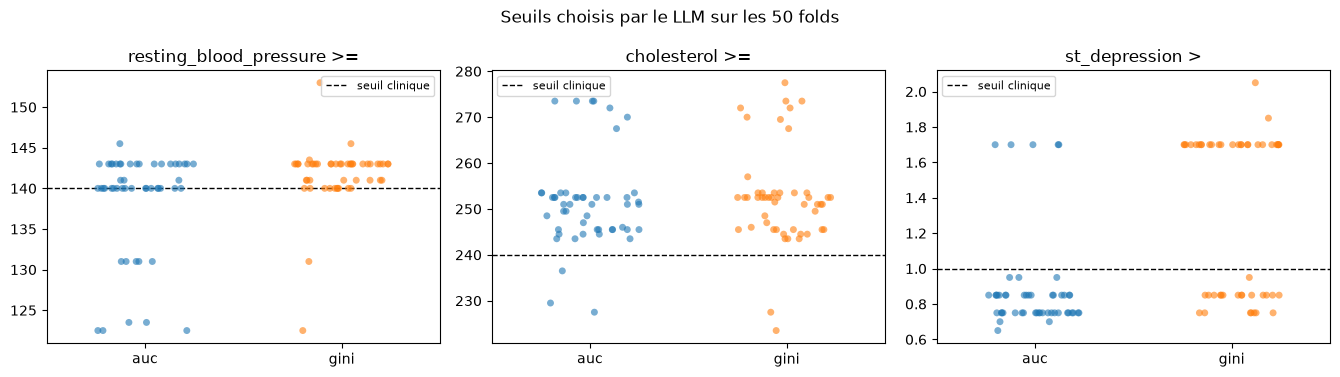

In [10]:
rows = []
for crit, per_fold in fold_thresholds.items():
    for g in groups.itertuples():
        t = np.array([f[g.group] for f in per_fold])
        rows.append({'critère': crit, 'groupe': g.group, 'règle': f'{g.variable} {g.operator}', 'clinique': g.clinical_threshold,
                     'moyenne': t.mean(), 'écart-type': t.std(), 'min': t.min(), 'max': t.max(),
                     '% folds = clinique': 100 * np.isclose(t, g.clinical_threshold).mean()})
stability = pd.DataFrame(rows)
display(stability.style.format(precision=2))

adjustable = [g for g in groups.itertuples() if stability[(stability.groupe == g.group)]['écart-type'].max() > 0]
if adjustable:
    fig, axes = plt.subplots(1, len(adjustable), figsize=(4.5 * len(adjustable), 3.8), squeeze=False)
    for ax, g in zip(axes[0], adjustable):
        data = pd.DataFrame({crit: [f[g.group] for f in fold_thresholds[crit]] for crit in tl.CRITERIA})
        sns.stripplot(data=data, ax=ax, jitter=0.25, alpha=0.6)
        ax.axhline(g.clinical_threshold, color='black', ls='--', lw=1, label='seuil clinique')
        ax.set_title(f'{g.variable} {g.operator}'); ax.legend(fontsize=8)
    plt.suptitle('Seuils choisis par le LLM sur les 50 folds'); plt.tight_layout()

## 6. Évaluation : le dataset enrichi bat-il la baseline ?

Même protocole que la baseline (mêmes 50 folds, mêmes 7 modèles). Dans chaque fold, les colonnes HPO sont construites avec les seuils de ce fold, puis le modèle est entraîné sur l'entraînement et évalué sur le test.

| Variante | Features | Ce qu'elle teste |
|---|---|---|
| **V0 Baseline** | 13 variables d'origine | référence |
| **clinique** | V0 + colonnes HPO, seuils cliniques du LLM (fixes) | l'apport des colonnes HPO **sans** ajustement |
| **ajusté AUC** | V0 + colonnes HPO, seuils ajustés par fold (critère AUC) | l'apport de l'ajustement |
| **ajusté Gini** | V0 + colonnes HPO, seuils ajustés par fold (impureté de Gini) | idem, autre critère |

Chaque version est testée avec trois jeux de variables :
- **(+ données)** : les 13 variables d'origine + les colonnes HPO ;
- **(HPO seul)** : âge + sexe + colonnes HPO, sans les autres variables brutes ;
- **(HPO pur)** : **uniquement les colonnes HPO créées**. Ça mesure l'information qu'elles portent à elles seules.

Les différences sont testées avec le **t-test corrigé de Nadeau & Bengio** (2003), apparié sur les mêmes folds, contre la baseline et contre la version « clinique ».

In [11]:
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.metrics import get_scorer
from scipy import stats

def corrected_ttest(a, b, test_train_ratio=1/4):
    '''t-test apparié corrigé (Nadeau & Bengio, 2003) pour CV répétée. Retourne (delta moyen, p-value).'''
    d = np.asarray(a) - np.asarray(b)
    var = d.var(ddof=1) * (1 / len(d) + test_train_ratio)
    if var == 0:
        return d.mean(), 1.0
    return d.mean(), 2 * stats.t.sf(abs(d.mean() / np.sqrt(var)), df=len(d) - 1)

INPUTS = {   # variables d'origine conservées à côté des colonnes HPO
    '+ données': (NUM_FEATS, CAT_FEATS),
    'HPO seul': (['age'], ['sex']),
    'HPO pur': ([], []),            # uniquement les colonnes HPO créées
}

def features(part, thresholds, inputs):
    hpo_cols = tl.build_features(part, num_rules, cat_rules, thresholds)
    num, cat = INPUTS[inputs]
    return pd.concat([part[num + cat], hpo_cols], axis=1), list(hpo_cols)

def run_fold(k, tr, te, thr_mode, inputs):
    thr = None if thr_mode == 'clinique' else fold_thresholds[thr_mode][k]
    X_tr, hpo_cols = features(df.iloc[tr], thr, inputs)
    X_te, _ = features(df.iloc[te], thr, inputs)
    hpo_cols = [c for c in hpo_cols if X_tr[c].nunique() > 1]     # colonnes constantes sur l'entraînement
    num, cat = INPUTS[inputs]
    out = {}
    for name, model in MODELS.items():
        pipe = make_pipeline(make_preprocessor(num, cat, hpo_cols), clone(model)).fit(X_tr, y.iloc[tr])
        out[name] = {m: get_scorer(s)(pipe, X_te, y.iloc[te]) for m, s in SCORING.items()}
    return out

VARIANTS_2 = {f'{mode} ({inputs})': (mode, inputs) for inputs in INPUTS for mode in ['clinique', 'auc', 'gini']}
fold_scores = {}
for vname, (mode, inputs) in VARIANTS_2.items():
    fold_scores[vname] = Parallel(n_jobs=-1)(delayed(run_fold)(k, tr, te, mode, inputs) for k, (tr, te) in enumerate(FOLDS))
    print('✔', vname)

✔ clinique (+ données)


✔ auc (+ données)


✔ gini (+ données)


✔ clinique (HPO seul)


✔ auc (HPO seul)


✔ gini (HPO seul)


✔ clinique (HPO pur)


✔ auc (HPO pur)


✔ gini (HPO pur)


In [12]:
def per_model(vname, metric='roc_auc'):
    return {m: np.array([f[m][metric] for f in fold_scores[vname]]) for m in MODELS}

auc = {'V0 Baseline': baseline_scores, **{v: per_model(v) for v in VARIANTS_2}}
table = pd.DataFrame({v: {m: s[m].mean() for m in MODELS} for v, s in auc.items()})
table.loc['Moyenne'] = table.mean()
table.style.format('{:.3f}').background_gradient(cmap='RdYlGn', axis=1).set_caption('ROC AUC moyenne (50 folds)')

,V0 Baseline,clinique (+ données),auc (+ données),gini (+ données),clinique (HPO seul),auc (HPO seul),gini (HPO seul),clinique (HPO pur),auc (HPO pur),gini (HPO pur)
LogReg,0.911,0.912,0.910,0.911,0.906,0.904,0.903,0.891,0.890,0.889
KNN,0.891,0.886,0.893,0.891,0.860,0.870,0.864,0.845,0.838,0.837
SVC (RBF),0.902,0.908,0.907,0.907,0.891,0.892,0.890,0.873,0.878,0.878
DecisionTree,0.800,0.794,0.795,0.795,0.837,0.839,0.832,0.845,0.843,0.840
RandomForest,0.902,0.905,0.904,0.903,0.875,0.884,0.879,0.831,0.841,0.843
GradBoosting,0.878,0.877,0.876,0.876,0.883,0.886,0.883,0.849,0.857,0.854
NaiveBayes,0.880,0.898,0.897,0.896,0.878,0.876,0.871,0.866,0.862,0.859
Moyenne,0.880,0.883,0.883,0.883,0.876,0.879,0.875,0.857,0.858,0.857


In [13]:
def stars(p):
    return '***' if p < 0.001 else '**' if p < 0.01 else '*' if p < 0.05 else ''

rows = []
for v in VARIANTS_2:
    ref = 'clinique ' + v.split(' ', 1)[1]
    for m in MODELS:
        d0, p0 = corrected_ttest(auc[v][m], auc['V0 Baseline'][m])
        d1, p1 = corrected_ttest(auc[v][m], auc[ref][m])
        rows.append({'variante': v, 'modèle': m, 'Δ vs baseline': f'{d0:+.3f} {stars(p0)}',
                     'Δ vs clinique': '—' if v == ref else f'{d1:+.3f} {stars(p1)}'})
deltas = pd.DataFrame(rows)
print("Δ ROC AUC (t-test corrigé : * p<0.05, ** p<0.01, *** p<0.001)")
display(deltas.pivot(index='modèle', columns='variante', values='Δ vs baseline')[list(VARIANTS_2)])
display(deltas.pivot(index='modèle', columns='variante', values='Δ vs clinique')[list(VARIANTS_2)])

Δ ROC AUC (t-test corrigé : * p<0.05, ** p<0.01, *** p<0.001)


variante,clinique (+ données),auc (+ données),gini (+ données),clinique (HPO seul),auc (HPO seul),gini (HPO seul),clinique (HPO pur),auc (HPO pur),gini (HPO pur)
modèle,,,,,,,,,
DecisionTree,-0.006,-0.005,-0.005,+0.037,+0.039,+0.032,+0.045,+0.043,+0.040
GradBoosting,-0.001,-0.002,-0.001,+0.005,+0.008,+0.005,-0.029,-0.021,-0.024
KNN,-0.005,+0.002,+0.000,-0.031,-0.021,-0.027,-0.046 *,-0.053 *,-0.054 *
LogReg,+0.001,-0.001,+0.000,-0.005,-0.007,-0.008,-0.020,-0.021,-0.023
NaiveBayes,+0.018 *,+0.017 *,+0.015,-0.002,-0.004,-0.009,-0.014,-0.018,-0.022
RandomForest,+0.003,+0.002,+0.002,-0.027,-0.018,-0.023,-0.071 ***,-0.060 **,-0.059 **
SVC (RBF),+0.006,+0.006,+0.006,-0.011,-0.010,-0.012,-0.029,-0.024,-0.024


variante,clinique (+ données),auc (+ données),gini (+ données),clinique (HPO seul),auc (HPO seul),gini (HPO seul),clinique (HPO pur),auc (HPO pur),gini (HPO pur)
modèle,,,,,,,,,
DecisionTree,—,+0.001,+0.001,—,+0.002,-0.005,—,-0.001,-0.005
GradBoosting,—,-0.001,-0.000,—,+0.003,+0.001,—,+0.008,+0.006
KNN,—,+0.007,+0.005,—,+0.009,+0.004,—,-0.007,-0.008
LogReg,—,-0.002,-0.001,—,-0.003,-0.003,—,-0.000,-0.002
NaiveBayes,—,-0.001,-0.002,—,-0.002,-0.007,—,-0.004,-0.007
RandomForest,—,-0.001,-0.001,—,+0.009,+0.004,—,+0.010,+0.012
SVC (RBF),—,-0.000,-0.000,—,+0.000,-0.001,—,+0.005,+0.005


## 7. Explicabilité : valeurs SHAP

**But** : voir quelles variables les modèles utilisent vraiment, dans quel sens, et **à partir de quelles valeurs**. En particulier, est-ce que les modèles retrouvent tout seuls les seuils cliniques (140 mmHg, 240 mg/dl, 1 mm) ?

Pour chaque patient et chaque variable, la valeur SHAP indique de combien cette variable a poussé la prédiction **vers `target = 1`** (valeur positive) ou **vers `target = 0`** (valeur négative). Avec la convention Kaggle conservée, `target = 0` regroupe les profils les plus pathologiques : une valeur SHAP négative pousse donc vers le profil « malade ».

**Choix de mise en œuvre**
- **Deux modèles** : la régression logistique (meilleur modèle, explainer linéaire exact, valeurs en *log-odds*) et la forêt aléatoire (explainer pour arbres exact, valeurs en *probabilité*). Les échelles des deux modèles ne sont donc pas comparables entre elles, seulement l'ordre des variables.
- **Sans fuite** : les valeurs SHAP sont calculées sur les patients de **test** des 5 folds de la première répétition de la validation croisée. Chaque patient est expliqué une fois, par un modèle qui ne l'a pas vu.
- **One-hot regroupé** : les valeurs SHAP des colonnes one-hot d'une variable catégorielle sont additionnées, pour revenir aux 13 variables d'origine.
- **Variante « + données »** (section 7.4) : colonnes HPO construites avec les seuils cliniques, puisque les seuils ajustés ne changent pas les performances (section 6).

In [14]:
import shap

SHAP_MODELS = {'LogReg': MODELS['LogReg'], 'RandomForest': MODELS['RandomForest']}
REP1 = FOLDS[:5]   # 1re répétition : chaque patient est exactement une fois dans le test
assert sorted(np.concatenate([te for _, te in REP1]).tolist()) == list(range(len(df)))

def source_var(col):
    """Colonne après prétraitement (ex. cat__chest_pain_type_asymptomatic) → variable d'origine."""
    kind, name = col.split('__', 1)
    if kind == 'cat':
        return next(c for c in CAT_FEATS if name.startswith(c + '_'))
    return name

def shap_oof(model_name, inputs=None):
    """Valeurs SHAP hors échantillon, regroupées par variable d'origine.
    inputs=None : baseline ; sinon un jeu de INPUTS, avec les colonnes HPO aux seuils cliniques.
    Retourne (valeurs SHAP, valeurs des variables), une ligne par patient."""
    all_shap, all_data = [], []
    for tr, te in REP1:
        if inputs is None:
            X_tr, X_te, (num, cat), hpo_cols = df.iloc[tr], df.iloc[te], (NUM_FEATS, CAT_FEATS), []
        else:
            X_tr, hpo_cols = features(df.iloc[tr], None, inputs)
            X_te, _ = features(df.iloc[te], None, inputs)
            hpo_cols = [c for c in hpo_cols if X_tr[c].nunique() > 1]
            num, cat = INPUTS[inputs]
        prep = make_preprocessor(num, cat, hpo_cols).fit(X_tr)
        Z_tr, Z_te = prep.transform(X_tr), prep.transform(X_te)
        model = clone(SHAP_MODELS[model_name]).fit(Z_tr, y.iloc[tr])
        if model_name == 'LogReg':
            masker = shap.maskers.Independent(Z_tr, max_samples=len(Z_tr))   # tout l'entraînement comme référence
            sv = shap.LinearExplainer(model, masker)(Z_te).values
        else:
            sv = shap.TreeExplainer(model)(Z_te).values
            sv = sv[..., 1] if sv.ndim == 3 else sv          # classe target = 1
        sv = pd.DataFrame(sv, index=X_te.index, columns=prep.get_feature_names_out())
        all_shap.append(sv.T.groupby(source_var).sum().T)
        all_data.append(X_te[num + cat + hpo_cols])
    values = pd.concat(all_shap).sort_index().fillna(0)      # colonne HPO absente d'un fold = contribution nulle
    data = pd.concat(all_data).sort_index()
    return values[data.columns], data

SHAP_RES = {(m, v): shap_oof(m, None if v == 'baseline' else v)
            for m in SHAP_MODELS for v in ['baseline', '+ données']}
print({k: v[0].shape for k, v in SHAP_RES.items()})

{('LogReg', 'baseline'): (296, 13), ('LogReg', '+ données'): (296, 29), ('RandomForest', 'baseline'): (296, 13), ('RandomForest', '+ données'): (296, 29)}


### 7.1 Importance globale (baseline)

Moyenne, sur les 296 patients, de la valeur absolue de SHAP : de combien chaque variable déplace la prédiction en moyenne, quel que soit le sens.

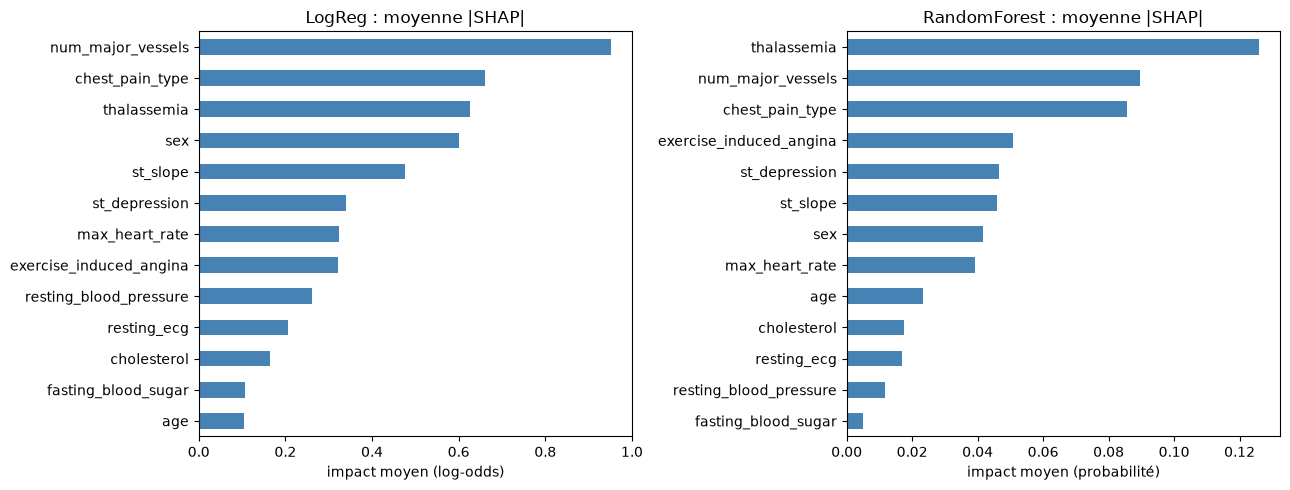

,num_major_vessels,chest_pain_type,thalassemia,sex,st_slope,st_depression,max_heart_rate,exercise_induced_angina,resting_blood_pressure,resting_ecg,cholesterol,fasting_blood_sugar,age
LogReg,1,2,3,4,5,6,7,8,9,10,11,12,13
RandomForest,2,3,1,7,6,5,8,4,12,11,10,13,9


In [15]:
def importance(values):
    return values.abs().mean().sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, m, unit in zip(axes, SHAP_MODELS, ['log-odds', 'probabilité']):
    imp = importance(SHAP_RES[(m, 'baseline')][0])
    imp.plot.barh(ax=ax, color='steelblue')
    ax.set_title(f'{m} : moyenne |SHAP|'); ax.set_xlabel(f'impact moyen ({unit})')
plt.tight_layout(); plt.show()

ranks = pd.DataFrame({m: importance(SHAP_RES[(m, 'baseline')][0]).rank(ascending=False).astype(int) for m in SHAP_MODELS})
ranks.sort_values('LogReg').T

### 7.2 Sens des effets

**Variables numériques** (beeswarm) : un point par patient, coloré selon la valeur de la variable (rouge = élevée, bleu = basse). Un point à gauche pousse vers `target = 0` (profil pathologique).

**Variables catégorielles** : valeur SHAP de chaque modalité (régression logistique).

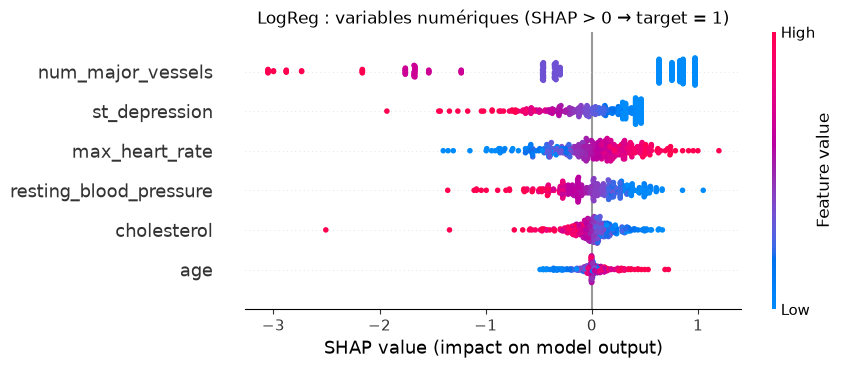

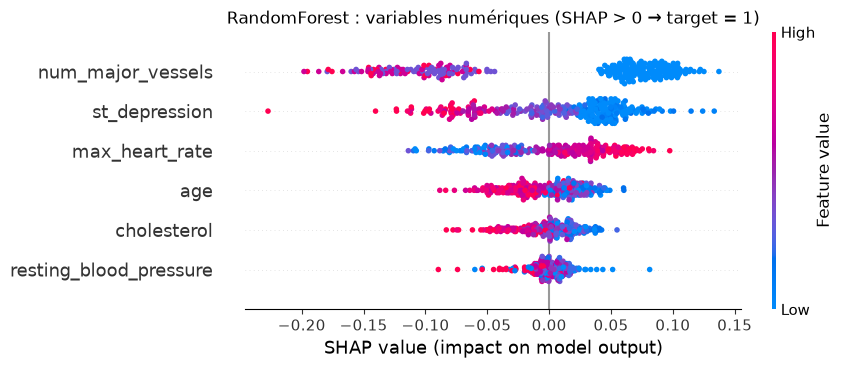

In [16]:
for m in SHAP_MODELS:
    values, data = SHAP_RES[(m, 'baseline')]
    v = values[NUM_FEATS]
    expl = shap.Explanation(values=v.to_numpy(), data=data[NUM_FEATS].to_numpy(float), feature_names=NUM_FEATS)
    shap.plots.beeswarm(expl, show=False, plot_size=(8, 3.6))
    plt.title(f'{m} : variables numériques (SHAP > 0 → target = 1)'); plt.show()

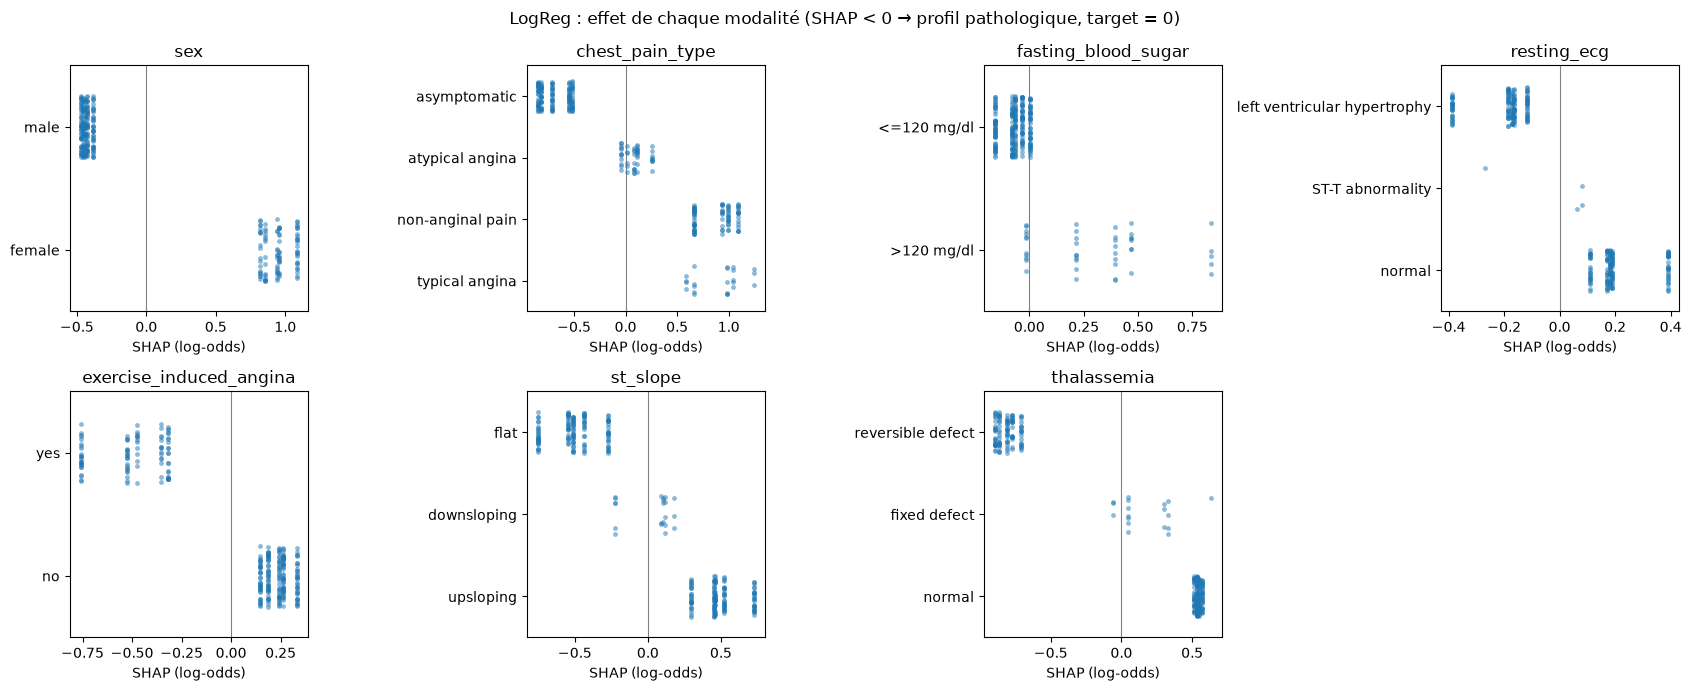

In [17]:
values, data = SHAP_RES[('LogReg', 'baseline')]
fig, axes = plt.subplots(2, 4, figsize=(17, 7))
for ax, c in zip(axes.flat, CAT_FEATS):
    order = values[c].groupby(data[c]).mean().sort_values().index
    sns.stripplot(x=values[c], y=data[c], order=order, ax=ax, alpha=0.5, jitter=0.25, size=3.5)
    ax.axvline(0, color='grey', lw=0.8); ax.set_title(c); ax.set_xlabel('SHAP (log-odds)'); ax.set_ylabel('')
axes.flat[-1].axis('off')
plt.suptitle('LogReg : effet de chaque modalité (SHAP < 0 → profil pathologique, target = 0)'); plt.tight_layout(); plt.show()

### 7.3 Courbes de dépendance : les modèles retrouvent-ils les seuils cliniques ?

Pour la **forêt aléatoire**, on trace la valeur SHAP de chaque patient en fonction de la valeur de la variable, avec une moyenne glissante. Un **saut** de la courbe indique une valeur de coupure utilisée par le modèle. On superpose le seuil clinique (noir) et la moyenne des seuils ajustés par gemma4 (critères AUC et Gini, section 5).

La régression logistique n'est pas tracée : elle est linéaire, sa courbe de dépendance est une droite par construction et ne peut pas montrer de seuil.

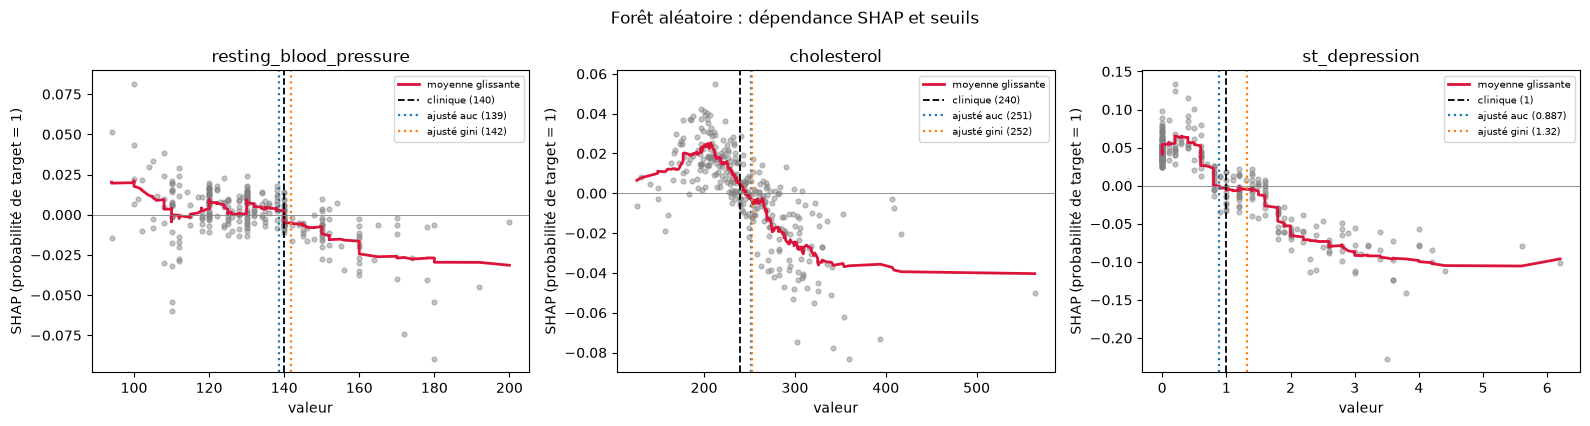

In [18]:
DEP_VARS = ['resting_blood_pressure', 'cholesterol', 'st_depression']
values, data = SHAP_RES[('RandomForest', 'baseline')]

fig, axes = plt.subplots(1, len(DEP_VARS), figsize=(16, 4.3))
for ax, var in zip(axes, DEP_VARS):
    x, s = data[var].astype(float), values[var]
    ax.scatter(x, s, s=12, alpha=0.45, color='grey')
    xs = x.sort_values()
    smooth = s[xs.index].rolling(25, center=True, min_periods=10).mean()
    ax.plot(xs, smooth, color='crimson', lw=2, label='moyenne glissante')
    g = groups[groups.variable == var].iloc[0]
    ax.axvline(g.clinical_threshold, color='black', ls='--', lw=1.3, label=f'clinique ({g.clinical_threshold:g})')
    for crit, col in [('auc', 'tab:blue'), ('gini', 'tab:orange')]:
        t = stability[(stability.groupe == g.group) & (stability['critère'] == crit)]['moyenne'].iloc[0]
        ax.axvline(t, color=col, ls=':', lw=1.6, label=f'ajusté {crit} ({t:.3g})')
    ax.axhline(0, color='grey', lw=0.6)
    ax.set_title(var); ax.set_xlabel('valeur'); ax.set_ylabel('SHAP (probabilité de target = 1)'); ax.legend(fontsize=7.5)
plt.suptitle('Forêt aléatoire : dépendance SHAP et seuils'); plt.tight_layout(); plt.show()

### 7.4 Variante « + données » : quel poids pour les colonnes HPO ?

On réentraîne les deux modèles avec les 13 variables d'origine **et** les colonnes HPO (seuils cliniques), puis on regarde :
1. la place des colonnes HPO (en orange) dans l'importance globale ;
2. si elles **prennent de l'importance à leur variable d'origine** : on compare l'importance de chaque variable source entre la baseline et « + données », et on la met à côté de l'importance des colonnes HPO qui en sont dérivées.

Remarque : *Angina pectoris* (HP_0001681) vient de `chest_pain_type` **et** de `exercise_induced_angina`, et *ST segment depression* (HP_0012250) de `st_depression` **et** de `st_slope`. Ces deux colonnes sont donc comptées pour chacune de leurs deux variables sources dans le tableau.

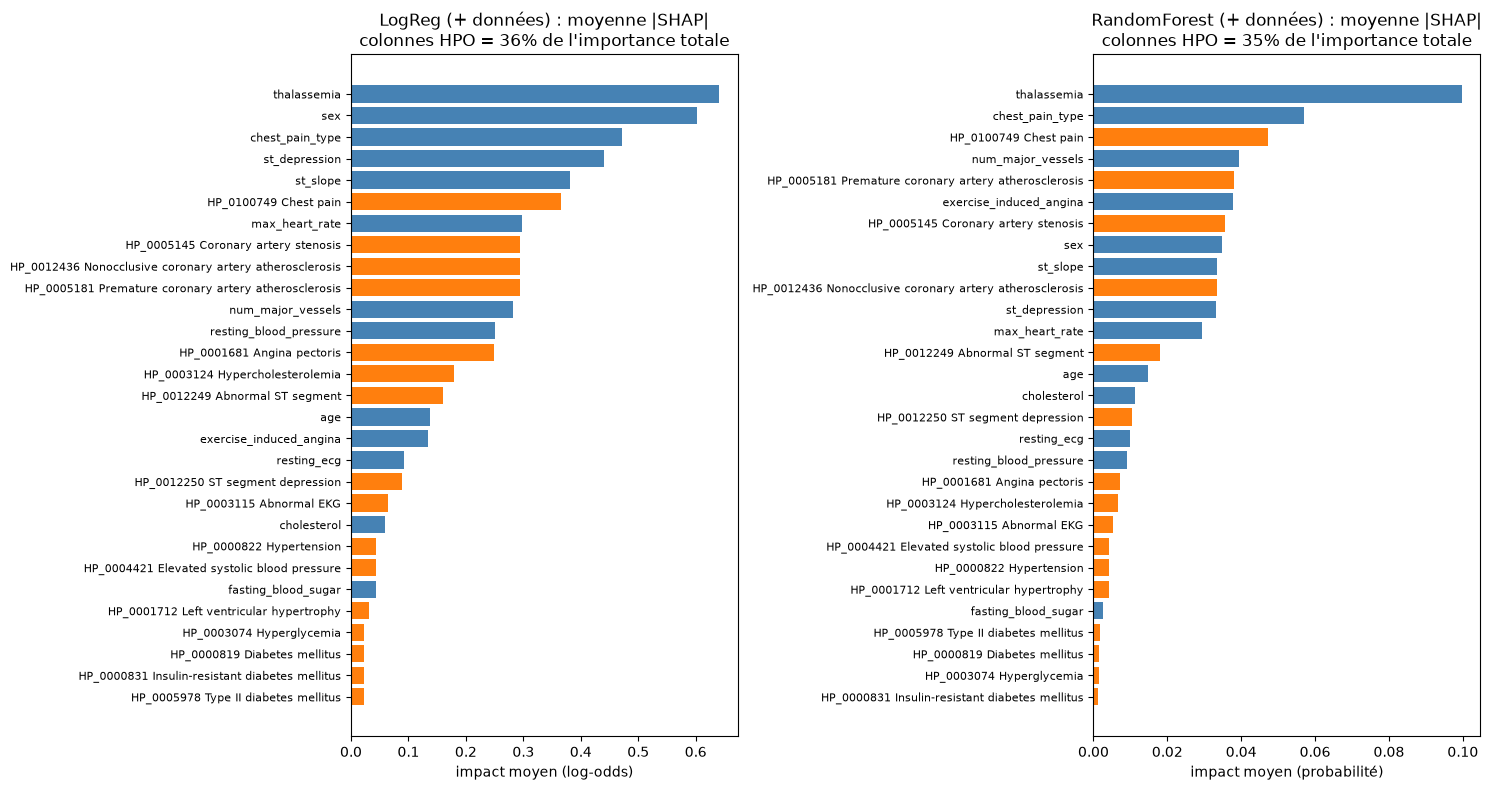

In [19]:
hp_label = {r.hp_id.replace(':', '_'): r.hp_label_hpo for r in pd.concat([num_rules, cat_rules]).itertuples()}
hp_source = pd.concat([num_rules, cat_rules]).assign(col=lambda d: d.hp_id.str.replace(':', '_')) \
              .groupby('col')['variable'].agg(lambda v: ' + '.join(sorted(set(v))))

fig, axes = plt.subplots(1, 2, figsize=(15, 8))
for ax, m, unit in zip(axes, SHAP_MODELS, ['log-odds', 'probabilité']):
    imp = importance(SHAP_RES[(m, '+ données')][0])
    names = [f'{c} {hp_label[c]}' if c in hp_label else c for c in imp.index]
    colors = ['tab:orange' if c in hp_label else 'steelblue' for c in imp.index]
    ax.barh(names, imp.to_numpy(), color=colors)
    share = imp[[c for c in imp.index if c in hp_label]].sum() / imp.sum()
    ax.set_title(f'{m} (+ données) : moyenne |SHAP|\ncolonnes HPO = {share:.0%} de l\'importance totale')
    ax.set_xlabel(f'impact moyen ({unit})'); ax.tick_params(axis='y', labelsize=8)
plt.tight_layout(); plt.show()

In [20]:
rows = []
for var in sorted(set(hp_source.str.split(' \+ ').explode())):
    cols = [c for c, src in hp_source.items() if var in src.split(' + ')]
    row = {'variable source': var, 'colonnes HPO dérivées': ', '.join(f'{c} ({hp_label[c]})' for c in cols)}
    for m in SHAP_MODELS:
        base = importance(SHAP_RES[(m, 'baseline')][0])
        enr = importance(SHAP_RES[(m, '+ données')][0])
        row[f'{m} : baseline'] = base[var]
        row[f'{m} : + données'] = enr[var]
        row[f'{m} : colonnes HPO'] = enr.reindex(cols).fillna(0).sum()
    rows.append(row)
transfer = pd.DataFrame(rows).set_index('variable source')
num_cols = [c for c in transfer if c != 'colonnes HPO dérivées']
display(transfer[num_cols].style.format('{:.3f}').set_caption('Moyenne |SHAP| : variable source, baseline contre « + données »'))
with pd.option_context('display.max_colwidth', None):
    display(transfer[['colonnes HPO dérivées']])

,LogReg : baseline,LogReg : + données,LogReg : colonnes HPO,RandomForest : baseline,RandomForest : + données,RandomForest : colonnes HPO
variable source,,,,,,
chest_pain_type,0.661,0.472,0.615,0.086,0.057,0.055
cholesterol,0.163,0.059,0.180,0.018,0.011,0.007
exercise_induced_angina,0.322,0.135,0.249,0.051,0.038,0.007
fasting_blood_sugar,0.107,0.043,0.087,0.005,0.002,0.006
num_major_vessels,0.953,0.281,0.883,0.089,0.039,0.107
resting_blood_pressure,0.262,0.251,0.088,0.012,0.009,0.009
resting_ecg,0.205,0.093,0.096,0.017,0.010,0.010
st_depression,0.340,0.441,0.088,0.047,0.033,0.011
st_slope,0.475,0.381,0.248,0.046,0.033,0.029


,colonnes HPO dérivées
variable source,
chest_pain_type,"HP_0001681 (Angina pectoris), HP_0100749 (Chest pain)"
cholesterol,HP_0003124 (Hypercholesterolemia)
exercise_induced_angina,HP_0001681 (Angina pectoris)
fasting_blood_sugar,"HP_0000819 (Diabetes mellitus), HP_0000831 (Insulin-resistant diabetes mellitus), HP_0003074 (Hyperglycemia), HP_0005978 (Type II diabetes mellitus)"
num_major_vessels,"HP_0005145 (Coronary artery stenosis), HP_0005181 (Premature coronary artery atherosclerosis), HP_0012436 (Nonocclusive coronary artery atherosclerosis)"
resting_blood_pressure,"HP_0000822 (Hypertension), HP_0004421 (Elevated systolic blood pressure)"
resting_ecg,"HP_0001712 (Left ventricular hypertrophy), HP_0003115 (Abnormal EKG)"
st_depression,HP_0012250 (ST segment depression)
st_slope,"HP_0012249 (Abnormal ST segment), HP_0012250 (ST segment depression)"


### 7.5 Ce qu'il faut retenir

**Importance (7.1)** : les deux modèles s'appuient d'abord sur les mêmes trois variables : `num_major_vessels`, `chest_pain_type` et `thalassemia` (scintigraphie au thallium). À l'inverse, `cholesterol`, `resting_blood_pressure`, `fasting_blood_sugar` et, pour la régression logistique, `age` comptent peu. Or ce sont justement les variables sur lesquelles on a ajusté des seuils (tension, cholestérol).

**Sens des effets (7.2)** : il est cliniquement cohérent. Poussent vers `target = 0` (profil pathologique) : plus de vaisseaux atteints, une dépression ST plus forte, une fréquence cardiaque maximale plus basse, une tension et un cholestérol plus élevés, le sexe masculin, l'absence de douleur thoracique (paradoxe déjà noté en section 1), l'angor d'effort, une pente ST plate et un défaut réversible au thallium. Deux effets sont contre-intuitifs mais faibles : une glycémie à jeun > 120 mg/dl pousse légèrement vers `target = 1`, et l'âge a un effet opposé dans les deux modèles. Pour la régression logistique, l'effet de l'âge est « à fréquence cardiaque égale », et les deux variables sont très liées.

**Seuils (7.3)** : la forêt aléatoire ne coupe pas les variables comme une règle binaire.
- `resting_blood_pressure` : effet **progressif**, sans saut net à 140. Un seuil unique résume mal la variable.
- `cholesterol` : la courbe passe de positive à négative **vers 230–250**, donc près du seuil clinique de 240 et des seuils ajustés (251–252). Mais elle continue de baisser jusqu'à environ 330 : il y a là aussi une pente, pas une marche.
- `st_depression` : c'est la seule variable avec de vraies **marches**. Une première vers 0,5–1, qui correspond au seuil clinique de 1 et au seuil ajusté AUC (0,89), et une seconde vers 1,6–2. Une colonne binaire unique ne garde que la première marche.

Conclusion : le modèle retrouve des zones de coupure proches des seuils cliniques, mais utilise **aussi** l'information de part et d'autre. C'est pourquoi les colonnes HPO seules (« HPO pur », section 6) font moins bien que les variables brutes.

**Colonnes HPO (7.4)** : dans la variante « + données », elles reçoivent environ **35 % de l'importance totale**, mais cette importance est **prise à leur variable d'origine**, pas ajoutée. Par exemple, pour la régression logistique, `num_major_vessels` passe de 0,95 à 0,28, et les trois colonnes coronariennes, qui ont exactement le même contenu, se partagent le reste (0,29 chacune). De même, `cholesterol` passe de 0,16 à 0,06 au profit de *Hypercholesterolemia*. Le modèle répartit la même information sur plusieurs colonnes équivalentes, ce qui est cohérent avec l'absence de gain d'AUC observée en section 6.